# Задание 4.9
## Остроугольный треугольник из частей случайно разделённого отрезка

### Условие:
Отрезок $[0,1]$ случайным образом делится на 3 части. Найти вероятность того, что из полученных отрезков можно сложить треугольник и этот треугольник будет остроугольным. Построить график $\hat p(A)$ для $N=150\,000$, привести оценку $\hat p$ и найти аналитическое решение.

### Модель:
Отрезок делят две независимые равномерные точки; пусть $x<y$ — их упорядоченные координаты. Стороны: $a=x$, $b=y-x$, $c=1-y$ ($a+b+c=1$). Упорядоченная пара $(x,y)$ равномерно распределена в треугольнике $\Omega=\{0\le x\le y\le1\}$, $\mu(\Omega)=\frac12$; тогда $(a,b)$ равномерно распределена в треугольнике $\{a,b\ge0,\ a+b\le1\}$ (площадь $\frac12$).

### Решение:
**Условия остроугольного треугольника.** Треугольник со сторонами $a,b,c$ **остроуголен**, если квадрат каждой стороны меньше суммы квадратов двух других:
$$a^2+b^2>c^2,\quad a^2+c^2>b^2,\quad b^2+c^2>a^2 .$$
(Из них уже следует неравенство треугольника.) Эту систему в координатах $(x,y)$ записали в листке (6 неравенств) — мы проверим её численно.

**Вычисление через «тупоугольные» треугольники.** События «можно сложить треугольник» (все стороны $<\frac12$; вероятность $\frac14$) разбиваются на остроугольные и тупоугольные. Найдём вероятность того, что треугольник существует и **тупой угол лежит против стороны $c$**: $c^2>a^2+b^2$ и $c<\frac12$.
Подставим $c=1-a-b$: $\ (1-a-b)^2-a^2-b^2=1-2a-2b+2ab>0\ \Leftrightarrow\ b<\dfrac{1-2a}{2(1-a)}$ (при $a<\frac12$), а условие $c<\frac12$ означает $b>\frac12-a$. Значит, для $a\in[0,\frac12]$:
$$\frac12-a<b<\frac{1-2a}{2(1-a)},\qquad \text{длина промежутка}=\frac{1-2a}{2}\Bigl(\frac1{1-a}-1\Bigr)=\frac{a(1-2a)}{2(1-a)} .$$
Площадь этой области (в плоскости $(a,b)$):
$$S_c=\int_0^{1/2}\frac{a(1-2a)}{2(1-a)}da=\frac12\int_0^{1/2}\Bigl(2a+1-\frac1{1-a}\Bigr)da=\frac12\Bigl[a^2+a+\ln(1-a)\Bigr]_0^{1/2}=\frac12\Bigl(\frac34-\ln2\Bigr).$$
(Деление: $\dfrac{a(1-2a)}{1-a}=2a+1-\dfrac1{1-a}$.) Так как вся площадь равна $\frac12$, вероятность $\mathbb P(\text{тупой угол против }c)=\dfrac{S_c}{1/2}=\dfrac34-\ln2$. Угол может быть тупым против любой из трёх сторон (события несовместны), поэтому
$$\mathbb P(\text{тупоугольный})=3\Bigl(\frac34-\ln2\Bigr)=\frac94-3\ln2,\qquad
\mathbb P(A)=\underbrace{\frac14}_{\text{существует}}-\Bigl(\frac94-3\ln2\Bigr)=\boxed{\,3\ln2-2\approx0{,}0794415\,}$$
**Согласование с решением из листка:** там $\mu(A)=\frac32\ln2-1$, $\mu(\Omega)=\frac12$, откуда $\mathbb P(A)=\dfrac{\frac32\ln2-1}{1/2}=3\ln2-2$ — то же самое.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from math import comb

rng = np.random.default_rng(2024)      # генератор псевдослучайных чисел; фиксированное «зерно» -> результаты воспроизводимы

def running_frequency(hits):
    # Относительная частота p̂_N = N(A)/N для N = 1, 2, ..., len(hits).
    # hits[i] = 1 (True), если в (i+1)-й реализации опыта событие A произошло, иначе 0.
    hits = np.asarray(hits, dtype=float)
    return np.cumsum(hits)/np.arange(1, len(hits) + 1)

def plot_frequency(ax, hits, p_exact, title, label=r'$\hat p_N(A)=N(A)/N$'):
    # График зависимости p̂(A) от числа реализаций N (статистическая устойчивость частоты):
    # синяя линия — относительная частота, красная — точная вероятность,
    # зелёные пунктиры — «коридор» P ± 3·sqrt(P(1−P)/N), в который частота попадает почти всегда.
    n = np.arange(1, len(hits) + 1)
    ph = np.cumsum(hits)/n
    sig = 3*np.sqrt(p_exact*(1 - p_exact)/n)
    ax.plot(n, ph, 'b-', lw=1, label=label)
    ax.axhline(p_exact, color='r', lw=1.5, label=f'P = {p_exact:.6f}')
    ax.plot(n, p_exact + sig, 'g--', lw=0.8, label=r'$P\pm3\sqrt{P(1-P)/N}$'); ax.plot(n, p_exact - sig, 'g--', lw=0.8)
    s = max(10, len(n)//50)                           # первые 2 % точек очень шумные; масштаб по y выбираем по остальным
    lo = min(ph[s:].min(), (p_exact - sig)[s:].min()); hi = max(ph[s:].max(), (p_exact + sig)[s:].max())
    pad = 0.1*(hi - lo); ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, len(hits)); ax.grid(alpha=0.3); ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('относительная частота')
    ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def plot_conditional(ax, hits_AB, hits_B, p_exact, title):
    # График условной частоты p̂(A|B) = N(A∩B)/N(B) в зависимости от общего числа реализаций N
    n = np.arange(1, len(hits_B) + 1); cB = np.cumsum(hits_B); cAB = np.cumsum(hits_AB)
    ph = np.where(cB > 0, cAB/np.maximum(cB, 1), np.nan)
    ax.plot(n, ph, 'b-', lw=1, label=r'$\hat p(A|B)=N(A\cap B)/N(B)$'); ax.axhline(p_exact, color='r', lw=1.5, label=f'значение {p_exact:.5f}')
    s = max(10, len(n)//20); v = ph[s:][~np.isnan(ph[s:])]; lo, hi = min(v.min(), p_exact), max(v.max(), p_exact); pad = 0.15*(hi - lo + 1e-9)
    ax.set_ylim(lo - pad, hi + pad); ax.set_xlim(0, len(hits_B)); ax.grid(alpha=0.3)
    ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('условная частота'); ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def table(hits, p_exact, Ns=(100, 1000, 10_000, 100_000, 1_000_000)):
    # Печатает оценки p̂ при разных N, отклонение от точного значения и границу 3σ
    hits = np.asarray(hits, dtype=float)
    print('       N        p̂(N)        |p̂ − P|      3σ_N')
    for N in Ns:
        if N <= len(hits):
            ph = hits[:N].mean(); print(f'{N:9d}   {ph:.7f}   {abs(ph - p_exact):.2e}   {3*np.sqrt(p_exact*(1 - p_exact)/N):.2e}')

### Проверка интеграла и вероятности «треугольник существует» (`sympy`)

In [2]:
import sympy as sp
a = sp.symbols('a', positive=True)
S_c = sp.integrate(a*(1 - 2*a)/(2*(1 - a)), (a, 0, sp.Rational(1, 2)))
print('S_c =', sp.simplify(S_c), '≈', float(S_c))
P_obtuse_c = 2*S_c                                   # деление на площадь всей области 1/2
P_exist = sp.Rational(1, 4)
P_acute = sp.simplify(P_exist - 3*P_obtuse_c)
print('P(тупой угол против c) =', sp.simplify(P_obtuse_c), '≈', float(P_obtuse_c))
print('P(остроугольный) =', P_acute, '≈', float(P_acute), ';   3·ln2 − 2 =', float(3*sp.log(2) - 2))
P_exact = float(P_acute)

S_c = 3/8 - log(2)/2 ≈ 0.028426409720027346
P(тупой угол против c) = 3/4 - log(2) ≈ 0.05685281944005469
P(остроугольный) = -2 + log(8) ≈ 0.07944154167983593 ;   3·ln2 − 2 = 0.07944154167983593


### Моделирование и проверка системы неравенств из листка

In [3]:
def acute(pts):
    # pts — массив (n × 2) пар точек; возвращает булев массив «из частей можно сложить остроугольный треугольник»
    x, y = np.minimum(pts[:, 0], pts[:, 1]), np.maximum(pts[:, 0], pts[:, 1])      # упорядочиваем: x ≤ y
    s = np.sort(np.column_stack([x, y - x, 1 - y]), axis=1)                        # стороны по возрастанию
    return (s[:, 0] + s[:, 1] > s[:, 2]) & (s[:, 0]**2 + s[:, 1]**2 > s[:, 2]**2)

N = 150_000
pts = rng.random((N, 2)); hit = acute(pts)
print(f'N = {N}: N(A) = {hit.sum()},  p̂ = {hit.mean():.7f}   (точное {P_exact:.7f})')

# оценка по 1 000 000 реализациям (как в листке)
big = acute(rng.random((1_000_000, 2))); print(f'N = 1 000 000: p̂ = {big.mean():.7f}')

# система неравенств из листка (x ≤ y): сверим с нашей классификацией на тех же точках
x, y = np.minimum(pts[:, 0], pts[:, 1]), np.maximum(pts[:, 0], pts[:, 1])
sheet = (y >= 0.5) & (x <= 0.5) & (y <= x + 0.5) & (x**2 + (1 - y)**2 >= (y - x)**2) & (x**2 + (y - x)**2 >= (1 - y)**2) & ((y - x)**2 + (1 - y)**2 >= x**2)
print('система из листка совпадает с нашей классификацией на всех точках:', bool((sheet == hit).all()))
table(hit, P_exact, Ns=(100, 1000, 10_000, 100_000, 150_000))

N = 150000: N(A) = 11919,  p̂ = 0.0794600   (точное 0.0794415)
N = 1 000 000: p̂ = 0.0796050
система из листка совпадает с нашей классификацией на всех точках: True
       N        p̂(N)        |p̂ − P|      3σ_N
      100   0.0600000   1.94e-02   8.11e-02
     1000   0.0840000   4.56e-03   2.57e-02
    10000   0.0820000   2.56e-03   8.11e-03
   100000   0.0791400   3.02e-04   2.57e-03
   150000   0.0794600   1.85e-05   2.09e-03


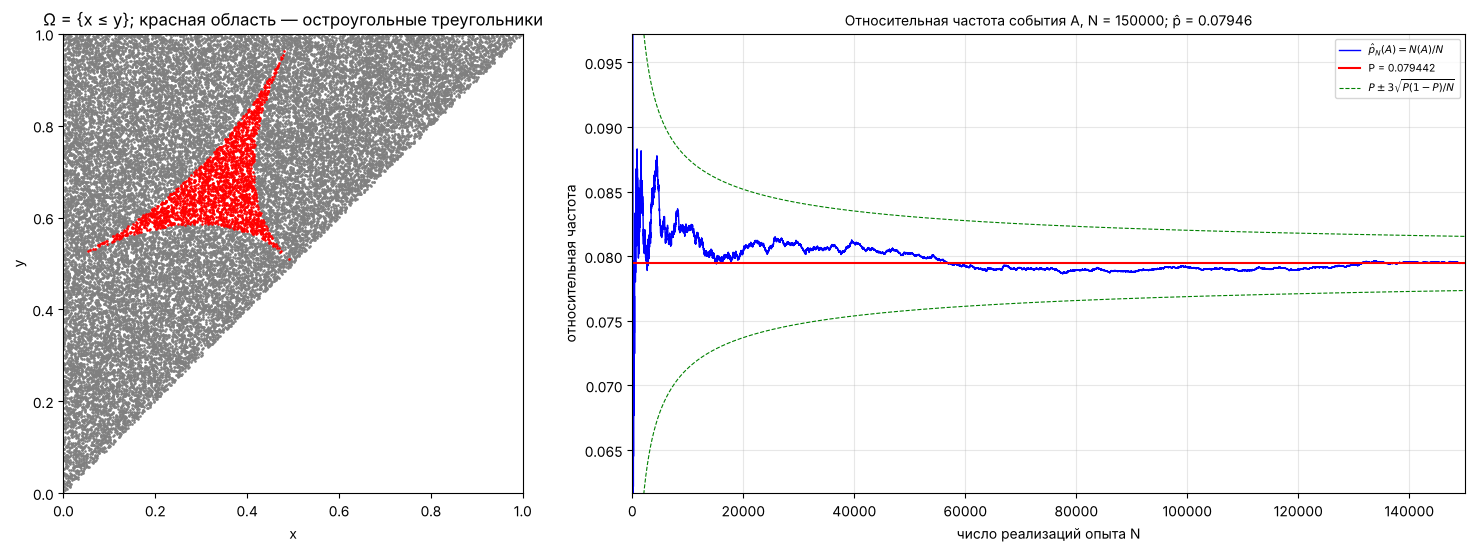

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={'width_ratios': [1, 1.7]})
m = 30_000
axs[0].scatter(x[:m][~hit[:m]], y[:m][~hit[:m]], s=0.8, c='gray'); axs[0].scatter(x[:m][hit[:m]], y[:m][hit[:m]], s=0.8, c='red')
axs[0].set_xlim(0, 1); axs[0].set_ylim(0, 1); axs[0].set_aspect('equal'); axs[0].set_xlabel('x'); axs[0].set_ylabel('y')
axs[0].set_title('Ω = {x ≤ y}; красная область — остроугольные треугольники')
plot_frequency(axs[1], hit, P_exact, f'Относительная частота события A, N = {N}; p̂ = {hit.mean():.5f}')
plt.tight_layout(); plt.savefig('task_4_9.png', dpi=130, bbox_inches='tight'); plt.show()

### Ответ:
$\mathbb P(A)=3\ln2-2\approx0{,}0794415$. Моделирование: $\hat p\approx0{,}079$ (значения для $N=150\,000$ и $10^6$ приведены выше); система неравенств из листка совпадает с нашей классификацией.